# Caos I: la ecuación de Lorenz
* https://drive.google.com/file/d/1Ez_vFce7wO49IoGmrzR8fOoK953KfUap/view

* prac video https://drive.google.com/file/d/1VpO0PbbjZTpG9zNAIG4lZbJGXS7GOBNn/view
* prac teo https://drive.google.com/file/d/1my8-XB78jmvU4XB4mNiW81k_kq-dFczM/view

In [ ]:
# a)
import numpy as np
#import scipy as sp
import scipy.signal as sgn
#import scipy.linalg as linalg
import matplotlib.pyplot as plt

In [3]:
# b)
#import ode

def euler(f, x, t, h, p):
    return x + h * f(x, t, p)


def rk4(f, x, t, h, p):
    k1 = f(x, t, p)
    k2 = f(x + 0.5 * h * k1, t + 0.5 * h, p)
    k3 = f(x + 0.5 * h * k2, t + 0.5 * h, p)
    k4 = f(x + h * k3, t + h, p)
    return x + h * (k1 + 2.0 * k2 + 2.0 * k3 + k4) / 6.0


def integrador_ode(m, f, xa, a, b, k, p, c=lambda x, t, p: x):
    assert k > 0
    n = len(xa)
    h = (b - a) / k
    w = np.zeros((n, k + 1))  # Produce un array con forma y tipo especificada con los parametros,
    # lleno de ceros. la forma puede ser espcificada con un entero o tupla (n,k+1)
    t = np.zeros(k + 1)
    w[:, 0] = xa  # actualiza la posicion inicial (columna de indice 0) de las variables con los valores
    # de las condiciones iniciales
    t[0] = a  # actualiza la posicion cero con el valor del tiempo inicial

    for j in range(k):  #Aca se produce la iteración en j

        t[j + 1] = t[j] + h  # iteracion tiempo
        w[:, j + 1] = m(f, w[:, j], t[j], h, p)  # iteracion de w
        w[:, j + 1] = c(w[:, j + 1], t[j + 1], p)  # condicion sobre w

    return t, w

## Ejercicio 2)

Considere el sistema de Ecuaciones Diferenciales Ordinarias de Lorenz

\begin{eqnarray}
\frac{dx}{dt} & = & s(y-x) \\
\frac{dy}{dt} & = & rx-y-xz \\
\frac{dz}{dt} & = & xy-bz
\end{eqnarray}

Sea $p=(s,r,b)$ el vector de parámetros.

**1)**
Usando el método de Runge-Kutta de orden 4, resuelva la ODE para las siguientes elecciones de las condiciones iniciales, de los parámetros y del intervalo de tiempo de integración:

&nbsp; &nbsp; **i)** $(x(0),y(0),z(0))=(1,0.5,0.1)$, $p=(10,0.5,8/3)$ y $t\in [0,10]$.

&nbsp; &nbsp; **ii)** $(x(0),y(0),z(0))=(1,0.5,0.1)$, $p=(10,10,8/3)$ y $t\in [0,20]$.

&nbsp; &nbsp; **iii)** $(x(0),y(0),z(0))=(1,0.5,0.1)$, $p=(10,28,8/3)$ y $t\in [0,50]$

**2)** Para cada caso calculado en el inciso **1)**, grafique, en un mismo gráfico, las curvas en función del tiempo $x(t)$ vs $t$, $y(t)$ vs $t$ y $z(t)$ vs $t$.

**3)**
Para cada caso calculado en el inciso **1)**, grafique paramétricamente en función del tiempo, y en 3 dimensiones, el vector que describe la trayectoria de la solución, i.e. grafique $(x(t),y(t),z(t))$ vs $t$.

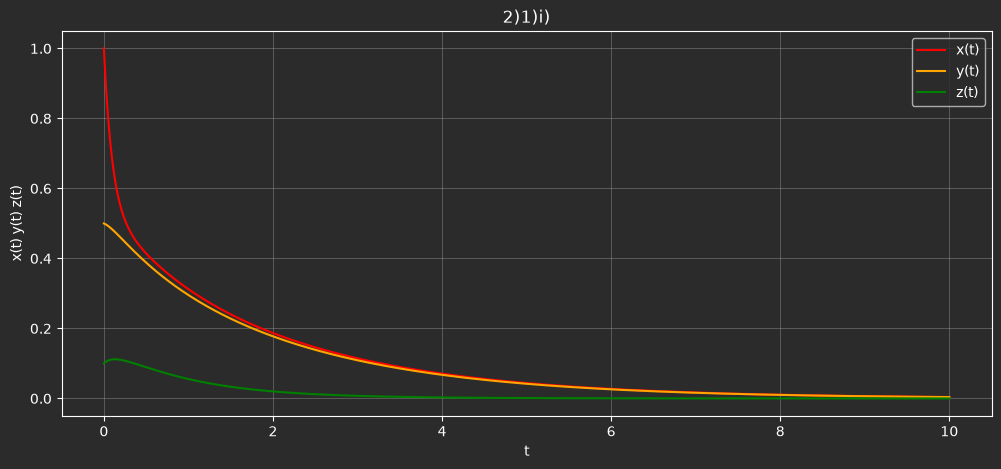

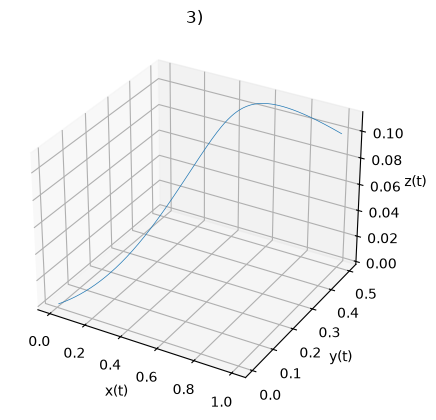

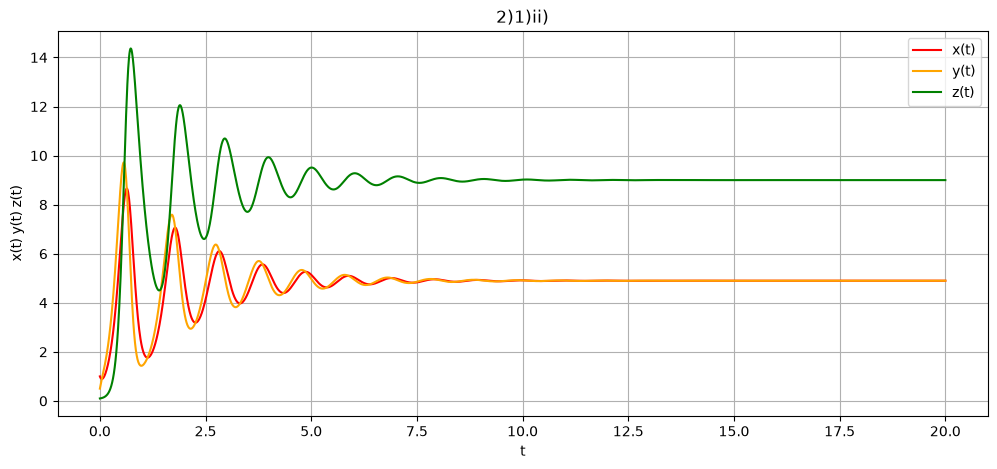

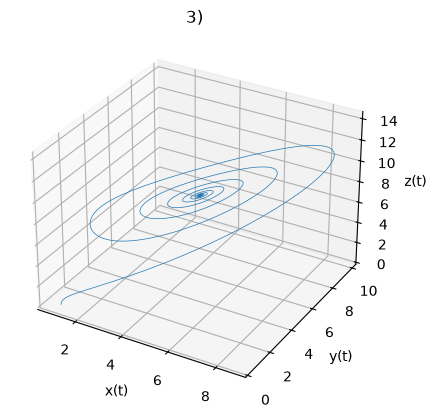

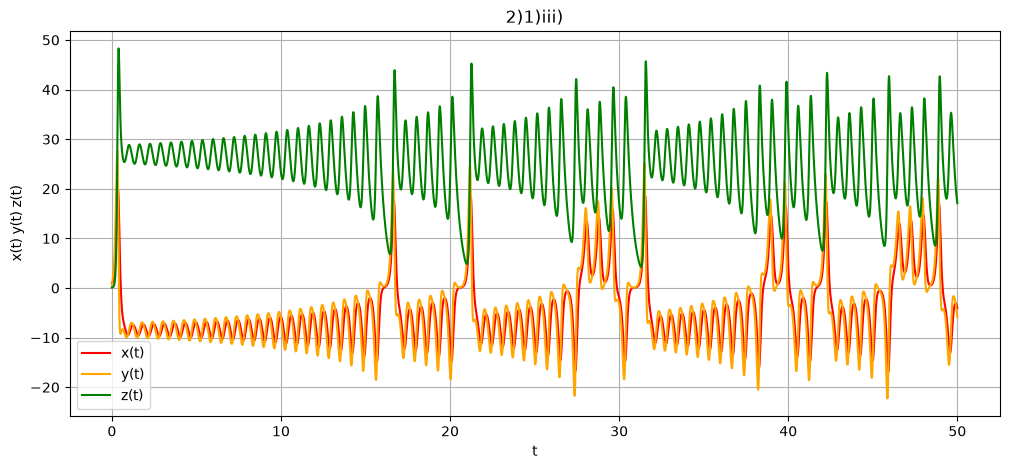

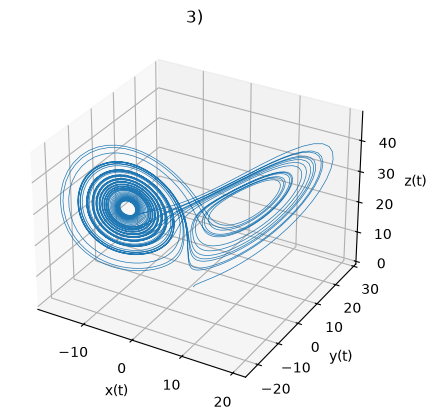

In [4]:
# 2.1)

def lorenz(w, t, p):
    s = p[0]
    r = p[1]
    b = p[2]

    x = w[0]
    y = w[1]
    z = w[2]

    dx = s * (y - x)
    dy = r * x - y - x * z
    dz = x * y - b * z

    return np.array([dx, dy, dz])


consigna = [
    {"title": "2)1)i)", "xyz": [1, 0.5, 0.1], "p": [10, 0.5, 8 / 3], "t": [0, 10]},
    {"title": "2)1)ii)", "xyz": [1, 0.5, 0.1], "p": [10, 10, 8 / 3], "t": [0, 20]},
    {"title": "2)1)iii)", "xyz": [1, 0.5, 0.1], "p": [10, 28, 8 / 3], "t": [0, 50]}
]

for item in consigna:
    ti, tf = item.get("t")[0], item.get("t")[1]
    p = item.get("p")
    xyz = item.get("xyz")

    h = 0.01
    k = int((tf - ti) / h)
    t, w = integrador_ode(rk4, lorenz, xyz, ti, tf, k, p)

    title = item.get("title")
    plt.figure(figsize=(12, 5))
    plt.xlabel('t')
    plt.ylabel('x(t) y(t) z(t)')
    plt.plot(t, w[0, :], label="x(t)", linestyle='-', c='red')
    plt.plot(t, w[1, :], label="y(t)", linestyle='-', c='orange')
    plt.plot(t, w[2, :], label="z(t)", linestyle='-', c='green')
    plt.title(f"{title}")
    plt.legend()
    plt.grid()
    plt.style.use('default')
    plt.show()
    #3) https://matplotlib.org/stable/gallery/mplot3d/index.html
    ax = plt.figure().add_subplot(projection='3d')
    ax.plot(w[0, :], w[1, :], w[2, :], lw=0.5)
    ax.set_xlabel("x(t)")
    ax.set_ylabel("y(t)")
    ax.set_zlabel("z(t)")
    ax.set_title("3)")
    plt.show()


## Ejercicio 3)

**1)** Repita el caso **1.iii)** del ejercicio **2)**, para $t\in [0,300]$, y eliminando el transiente que se observa antes de "converger" al atractor.

**2)** Identifique los máximos locales de la curva $z(t)$ obtenida en el inciso **1)**, y enumérelos como $z_1,z_2,...,z_i,...,z_n$.

**3)** Grafique $z_{i+1}$ vs $z_i$ para todo $i\in\{1,2,...,n-1\}$.

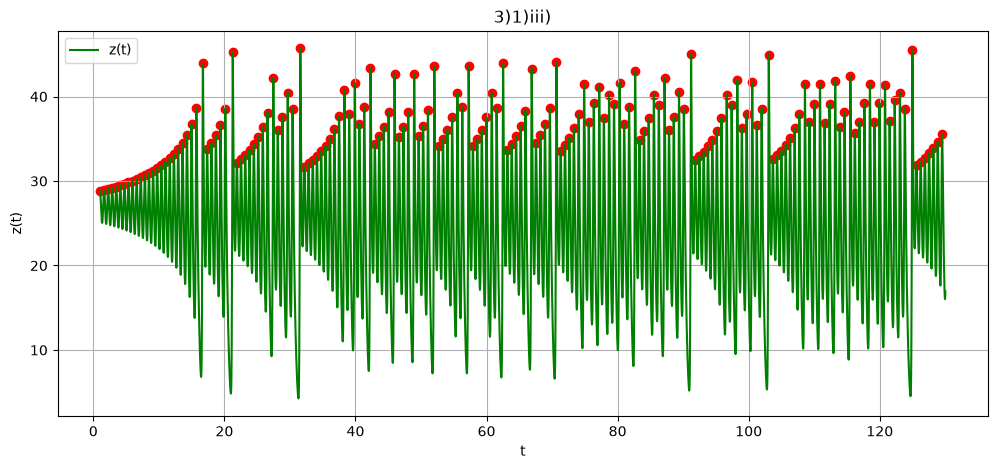

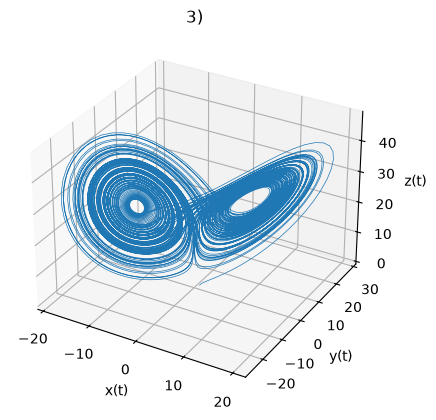

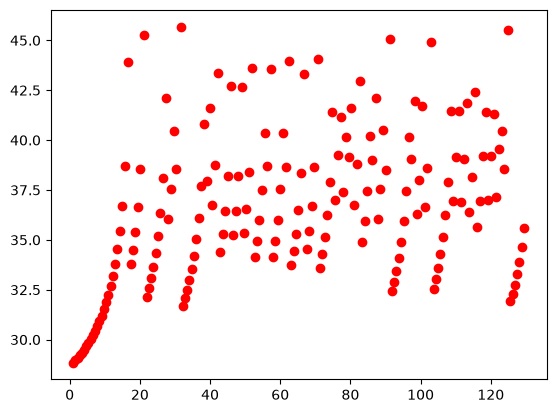

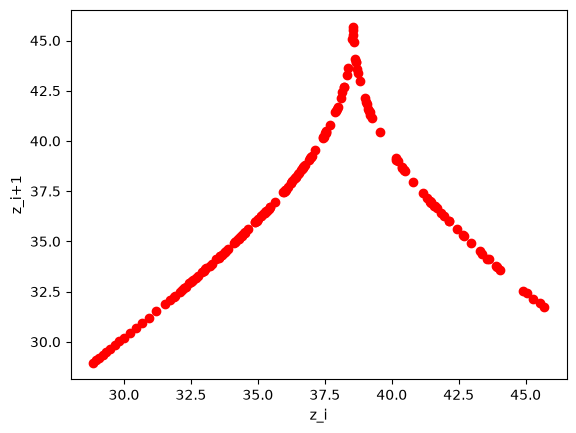

In [24]:
# 3.1)
from scipy.signal import find_peaks

consigna = [
    {"title": "3)1)iii)", "xyz": [1, 0.5, 0.1], "p": [10, 28, 8 / 3], "t": [0, 130]}
]

for item in consigna:
    ti, tf = item.get("t")[0], item.get("t")[1]
    p = item.get("p")
    xyz = item.get("xyz")

    h = 0.01
    k = int((tf - ti) / h)
    t, w = integrador_ode(rk4, lorenz, xyz, ti, tf, k, p)

    z_peaks_indx = np.array(find_peaks(w[2])[0])
    z_peak = w[2][z_peaks_indx][1:]
    t_peaks = t[z_peaks_indx][1:]

    title = item.get("title")
    plt.figure(figsize=(12, 5))
    plt.xlabel('t')
    plt.ylabel('z(t)')
    plt.plot(t[100:], w[2, 100:], label="z(t)", linestyle='-', c='green')
    plt.title(f"{title}")
    plt.legend()
    plt.grid()
    plt.style.use('default')
    plt.scatter(t_peaks, z_peak, c='red', label="z_max(t)")
    plt.show()
    #3) https://matplotlib.org/stable/gallery/mplot3d/index.html
    ax = plt.figure().add_subplot(projection='3d')
    ax.plot(w[0, :], w[1, :], w[2, :], lw=0.5)
    ax.set_xlabel("x(t)")
    ax.set_ylabel("y(t)")
    ax.set_zlabel("z(t)")
    ax.set_title("3)")
    plt.show()

    #

    plt.scatter(t_peaks, z_peak, c='red', label="z_max(t)")
    plt.show()

    #
    plt.scatter(z_peak[:-1], z_peak[1:], c='red', label="z_max(t)")
    plt.xlabel('z_i')
    plt.ylabel('z_i+1')
    plt.show()


## Ejercicio 4)

**1)** Con la intención de imitar un set de datos, agregue ruido Gaussiano de varianza $\sigma^2=1$ a la curva $z(t)$ vs $t$ generada en el inciso **1)** del ejercicio **3)**. Llamaremos a esta nueva curva $\tilde{z}(t)$ vs $t$. Grafíquela.

**2)** Utilice algún algoritmo de suavizado de curvas (ver función `savgol_filter` de la librería `scipy.signal`) para suavizar $\tilde{z}(t)$ vs $t$. Llame $\hat{z}(t)$ vs $t$ a la curva suavizada.

**3)** Utilice la curva suavizada del inciso **2)** para identificar los tiempos $\hat{t}_1$,$\hat{t}_2$,...,$\hat{t}_n$ en los cuales ocurre los máximos locales $\hat{z}_1=\hat{z}(\hat{t}_1)$, $\hat{z}_2=\hat{z}(\hat{t}_2)$, ...,$\hat{z}_n=\hat{z}(\hat{t}_n)$ correspondientes.

Calcule además los valores de la curva sin suavizar en dichos tiempos, i.e. calcule $\tilde{z}_1=\tilde{z}(\hat{t_1})$, $\tilde{z}_2=\tilde{z}(\hat{t_2})$, ..., $\tilde{z}_n=\tilde{z}(\hat{t_n})$.

**4)** Grafique la curva suavizada $\tilde{z}(t)$ vs $t$.

Agregue al gráfico los máximos $(\tilde{z}_i,\hat{t}_i)$ con puntos azules, y los máximos $(\hat{z}_i,\hat{t}_i)$ con puntos rojos.

Que observa?

**5)** Grafique $\tilde{z}_{i+1}$ vs $\tilde{z}_i$ para todo $i\in\{1,2,...,n-1\}$.

**6)** Grafique $\hat{z}_{i+1}$ vs $\hat{z}_i$ para todo $i\in\{1,2,...,n-1\}$.

**7)** Comparando los resultados de los incisos **5)** y **6)** con los del gráfico del inciso **3)** del ejercicio **3)**.

Discuta y comente.

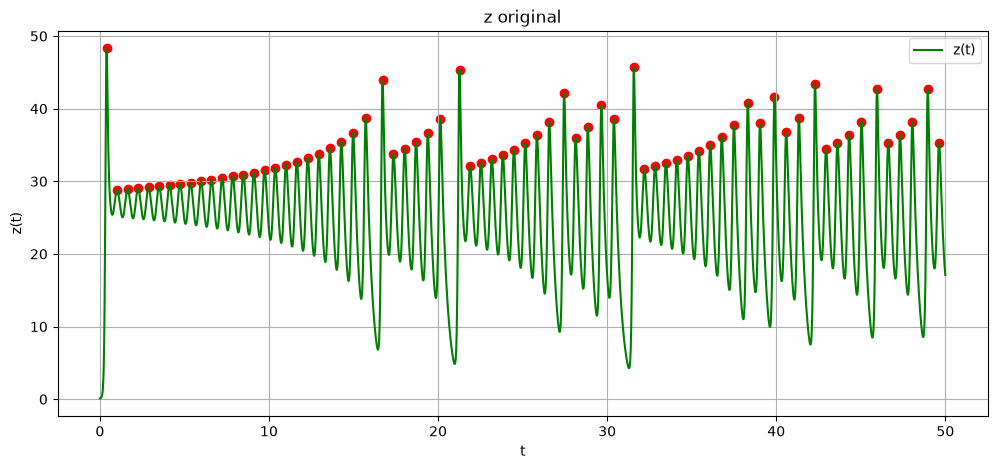

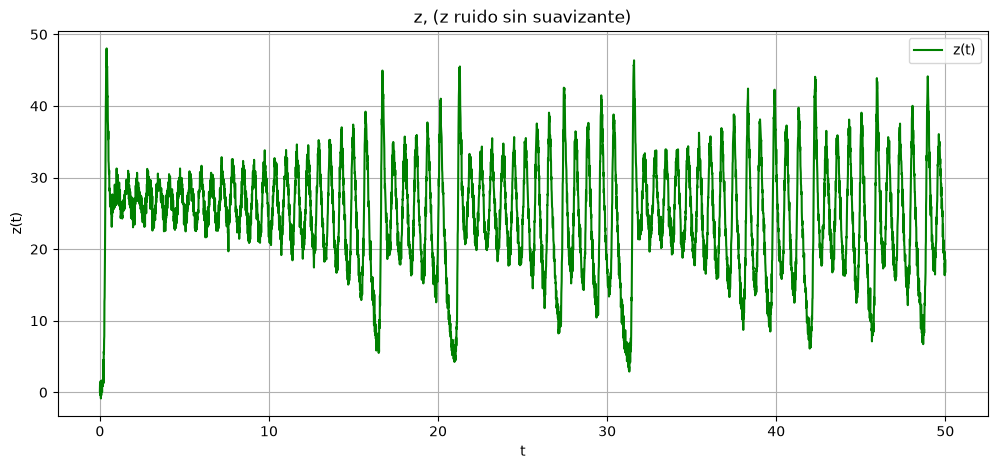

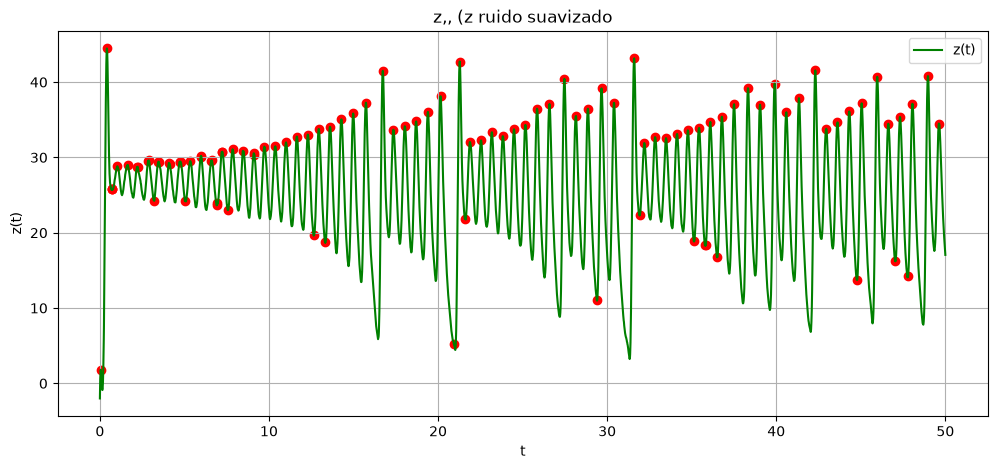

In [48]:
# 4.1)


consigna = [
    {"title": "3)1)iii)", "xyz": [1, 0.5, 0.1], "p": [10, 28, 8 / 3], "t": [0, 50]}
]

for item in consigna:
    ti, tf = item.get("t")[0], item.get("t")[1]
    p = item.get("p")
    xyz = item.get("xyz")

    h = 0.01
    k = int((tf - ti) / h)
    t, w = integrador_ode(rk4, lorenz, xyz, ti, tf, k, p)

    z = w[2]
    noise = np.random.normal(loc=0, scale=1, size=len(z))
    z_noise = z + noise


    plt.figure(figsize=(12, 5))
    plt.xlabel('t')
    plt.ylabel('z(t)')
    plt.plot(t, z, label="z(t)", linestyle='-', c='green')
    plt.title(f"z original")
    plt.legend()
    plt.grid()
    plt.style.use('default')

    z_peaks_indx = np.array(find_peaks(w[2])[0])
    z_peak = w[2][z_peaks_indx]
    t_peaks = t[z_peaks_indx]

    plt.style.use('default')
    plt.scatter(t_peaks, z_peak, c='red', label="z_max(t)")
    plt.show()

    plt.figure(figsize=(12, 5))
    plt.xlabel('t')
    plt.ylabel('z(t)')
    plt.plot(t, z_noise, label="z(t)", linestyle='-', c='green')
    plt.title(f"z, (z ruido sin suavizante)")
    plt.legend()
    plt.grid()
    plt.style.use('default')
    plt.show()


    z_noise_soft = sgn.savgol_filter(z_noise,50,5)
    plt.figure(figsize=(12, 5))
    plt.xlabel('t')
    plt.ylabel('z(t)')
    plt.plot(t, z_noise_soft    , label="z(t)", linestyle='-', c='green')
    plt.title(f"z,, (z ruido suavizado")
    plt.legend()
    plt.grid()
    plt.style.use('default')

    z_peaks_indx_2 = np.array(find_peaks(z_noise_soft)[0])
    z_peak_2 = z_noise_soft[z_peaks_indx_2]
    t_peaks_2 = t[z_peaks_indx_2]

    plt.style.use('default')
    plt.scatter(t_peaks_2, z_peak_2, c='red', label="z_max(t)")
    plt.show()




In [ ]:
# 4.7)

**Discusión:** Bla bla bla... (Pone lo que digas en voz alta)